# Tutorial 1 · Mouse midbrain development
Dorsal midbrain (Stereo-seq) at E12.5, E14.5 and E16.5. Radial glia (RGC) give rise to neuroblasts (NeuB) and glioblasts (GlioB).
We ask which RGC become glioblasts, where they sit, and which received signals are associated with this fate.

In [1]:
import anndata as ad, numpy as np, matplotlib.pyplot as plt
import nichefate as nf
DATA = "../tutorial_data/"
ages = ["E12.5", "E14.5", "E16.5"]
ads = [ad.read_h5ad(DATA + f"midbrain_{a}.h5ad") for a in ages]
for a, x in zip(ages, ads): print(a, x.n_obs, "cells", x.obs.cell_type.astype(str).value_counts().to_dict())

E12.5 2237 cells {'RGC': 1708, 'GlioB': 269, 'NeuB': 260}
E14.5 974 cells {'RGC': 586, 'NeuB': 236, 'GlioB': 152}
E16.5 1370 cells {'RGC': 466, 'GlioB': 462, 'NeuB': 442}


## 1 · Niche of every cell
Received ligand-receptor signals (per pathway) and a graph-convolutional embedding of each cell's neighbourhood, computed jointly for all sections.

In [2]:
nf.compute_niche(ads)

2606 shared genes, 34 ligand-receptor pairs, 16 signals (pathway)


C:\Users\au827475\Dropbox\Niche-FATE\nichefate\_gnn.py:14: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  At = torch.sparse_coo_tensor(np.vstack([A.row, A.col]), A.data.astype(np.float32), A.shape, device=device).coalesce()


niche computed for 3 sections: [2237, 974, 1370] cells


## 2 · Match cells across time

       GlioB  NeuB   RGC
GlioB   0.34  0.19  0.47
NeuB    0.17  0.25  0.58
RGC     0.11  0.16  0.73


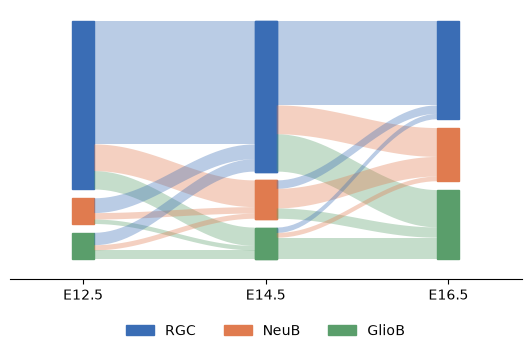

In [3]:
r1 = nf.match(ads[0], ads[1], groupby="cell_type")
r2 = nf.match(ads[1], ads[2], groupby="cell_type")
print(r1.transitions.round(2))
nf.pl.sankey([r1, r2], ["RGC", "NeuB", "GlioB"], labels=ages); plt.show()

## 3 · Fate of each radial glial cell
P(glioblast | neuroblast or glioblast) for every E12.5 RGC.

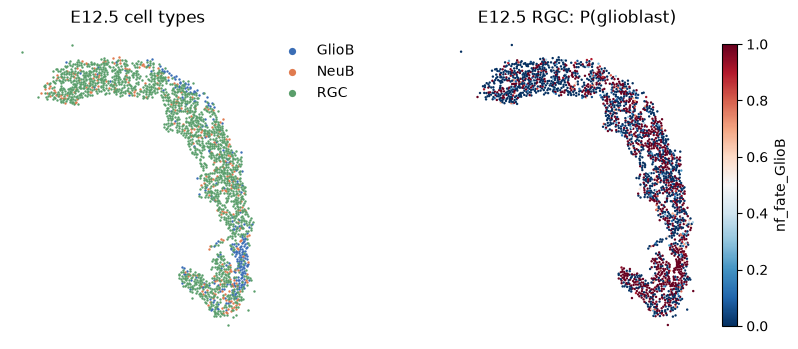

In [4]:
p = nf.fate(r1, "GlioB", among=["NeuB", "GlioB"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
nf.pl.groups_map(ads[0], "cell_type", ax=ax[0]); ax[0].set_title("E12.5 cell types")
nf.pl.fate_map(ads[0], "nf_fate_GlioB", ax=ax[1], title="E12.5 RGC: P(glioblast)"); plt.show()

## 4 · Check against the next stage
Along the dorsal midbrain arc, the share of glioblasts observed at E14.5 rises from one end to the other. The fate predicted for
E12.5 RGC (which never saw E14.5 labels per position) should follow the same profile; without the niche module it follows it less well.

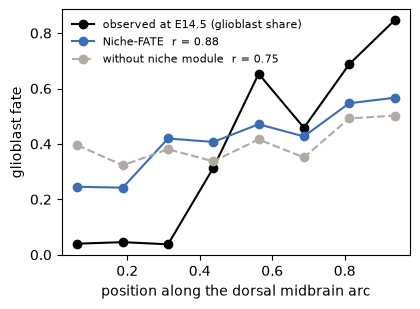

In [5]:
from sklearn.manifold import Isomap
def arc(xy):                                     # position along the arc, 0 -> 1
    s = Isomap(n_neighbors=15, n_components=1).fit_transform(xy)[:, 0]
    if xy[np.argmin(s), 0] > xy[np.argmax(s), 0]: s = -s
    return (s - s.min()) / (s.max() - s.min())
def profile(pos, v, bins=8):
    b = np.minimum((pos * bins).astype(int), bins - 1)
    return np.array([v[b == k].mean() if (b == k).sum() >= 5 else np.nan for k in range(bins)])
corr = lambda a, b: np.corrcoef(a[np.isfinite(a) & np.isfinite(b)], b[np.isfinite(a) & np.isfinite(b)])[0, 1]
ct2 = ads[1].obs.cell_type.values; prog = np.isin(ct2, ["NeuB", "GlioB"])
observed = profile(arc(ads[1].obsm["spatial"])[prog], (ct2[prog] == "GlioB").astype(float))
rgc = (ads[0].obs.cell_type == "RGC").values; pos0 = arc(ads[0].obsm["spatial"])[rgc]
predicted = profile(pos0, ads[0].obs["nf_fate_GlioB"].values[rgc])
r0 = nf.match(ads[0], ads[1], groupby="cell_type", w_signal=0, w_niche=0)          # same model without the niche module
nf.fate(r0, "GlioB", among=["NeuB", "GlioB"], key_added="fate_no_niche")
no_niche = profile(pos0, ads[0].obs["fate_no_niche"].values[rgc])
x = (np.arange(8) + 0.5) / 8
plt.figure(figsize=(4.5, 3.2))
plt.plot(x, observed, "k-o", label="observed at E14.5 (glioblast share)")
plt.plot(x, predicted, "-o", color="#3a6db5", label=f"Niche-FATE  r = {corr(predicted, observed):.2f}")
plt.plot(x, no_niche, "--o", color="#b0aaa3", label=f"without niche module  r = {corr(no_niche, observed):.2f}")
plt.xlabel("position along the dorsal midbrain arc"); plt.ylabel("glioblast fate"); plt.legend(frameon=False, fontsize=8); plt.show()

## 5 · Signals associated with fate
Which received signals are linked to the glioblast fate (positive) or the neuroblast fate (negative), adjusting for each cell's own expression state and local density; p-values from spatial block permutation.

  signal      r      z      p      q  stable
0   NRXN  0.050  1.943  0.048  0.069    True
1    MPZ  0.044  1.622  0.093  0.114    True
2  EPHB2  0.033  1.284  0.196  0.224    True
3   EPHA -0.025 -0.983  0.329  0.329    True
4     MK -0.034 -1.178  0.222  0.237   False
5   NCAM -0.053 -1.970  0.052  0.069    True
6   AGRN -0.081 -2.811  0.004  0.007    True
7    PTN -0.080 -2.861  0.003  0.006    True
8   CADM -0.074 -2.865  0.007  0.011    True
9    JAM -0.088 -3.349  0.002  0.005    True


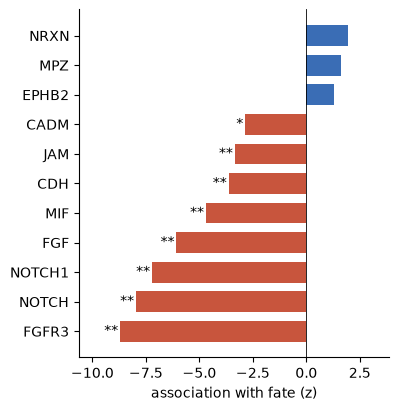

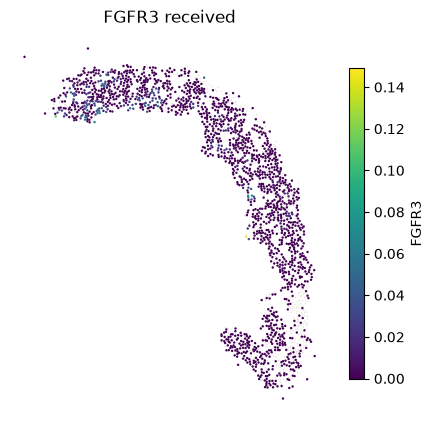

In [6]:
d = nf.drivers(r1, p, cells=["RGC"], composition_key="cell_type")
print(d.head(10).round(3))
nf.pl.drivers(d, top=8, alpha=None); plt.show()
top = d.signal[d.r.abs().idxmax()]                       # strongest association (either direction)
nf.pl.signal_map(ads[0], top, cells=(ads[0].obs.cell_type == "RGC").values); plt.show()